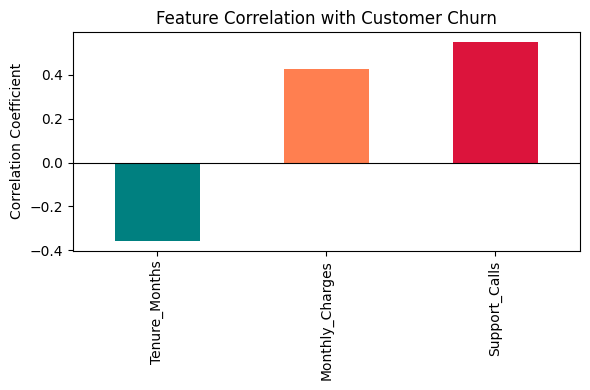

Accuracy:  0.9833
Precision: 0.9885
Recall:    0.9885

Detailed Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.97      0.97        33
           1       0.99      0.99      0.99        87

    accuracy                           0.98       120
   macro avg       0.98      0.98      0.98       120
weighted avg       0.98      0.98      0.98       120



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report

# 1. Generate realistic customer service dataset
np.random.seed(42)
n_customers = 600

data = {
    'Tenure_Months': np.random.randint(1, 60, n_customers),
    'Monthly_Charges': np.random.uniform(20.0, 120.0, n_customers),
    'Support_Calls': np.random.randint(0, 10, n_customers)
}
df = pd.DataFrame(data)

# Calculate churn probability based on service indicators
churn_logit = (0.04 * df['Monthly_Charges']) + (0.45 * df['Support_Calls']) - (0.06 * df['Tenure_Months']) - 2.0
churn_prob = 1 / (1 + np.exp(-churn_logit))
df['Churn'] = (churn_prob > 0.5).astype(int)

# 2. Exploratory Data Analysis (EDA): Feature Correlation
correlations = df.corr()['Churn'].drop('Churn')

plt.figure(figsize=(6, 4))
correlations.plot(kind='bar', color=['teal', 'coral', 'crimson'])
plt.title('Feature Correlation with Customer Churn')
plt.ylabel('Correlation Coefficient')
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('feature_correlations.png')
plt.show()

# 3. Binary Classification Pipeline
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Baseline Classification Algorithm (Logistic Regression)
classifier = LogisticRegression()
classifier.fit(X_train_scaled, y_train)

# 4. Evaluation Benchmarks on Test Data Split
y_pred = classifier.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}\n")
print("Detailed Classification Report:\n", classification_report(y_test, y_pred))